In [1]:
import torch
from datasets import load_from_disk

print("Jupyter Notebook Working!")
print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

Jupyter Notebook Working!
PyTorch Version: 2.10.0+cu128
CUDA Available: True


In [2]:

from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_from_disk

# Find project root
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "oct2017"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "figures"
METRICS_DIR = PROJECT_ROOT / "outputs" / "metrics"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

# Load locally saved dataset
ds = load_from_disk(str(DATA_PATH))

train_data = ds["train"]
test_data = ds["test"]

class_names = train_data.features["label"].names

print("Dataset loaded successfully!")
print("Training images:", len(train_data))
print("Testing images:", len(test_data))
print("Classes:", class_names)


Dataset loaded successfully!
Training images: 108309
Testing images: 1000
Classes: ['CNV', 'DME', 'DRUSEN', 'NORMAL']


In [3]:

train_counts = Counter(train_data["label"])
test_counts = Counter(test_data["label"])

distribution = pd.DataFrame({
    "Class": class_names,
    "Train": [
        train_counts.get(i, 0)
        for i in range(len(class_names))
    ],
    "Test": [
        test_counts.get(i, 0)
        for i in range(len(class_names))
    ]
})

distribution["Total"] = (
    distribution["Train"] + distribution["Test"]
)

distribution["Train_Percentage"] = (
    distribution["Train"] / len(train_data) * 100
).round(2)

display(distribution)

distribution.to_csv(
    METRICS_DIR / "class_distribution.csv",
    index=False
)

print("Class distribution saved!")


,Class,Train,Test,Total,Train_Percentage
0,CNV,37205,250,37455,34.35
1,DME,11348,250,11598,10.48
2,DRUSEN,8616,250,8866,7.96
3,NORMAL,51140,250,51390,47.22


Class distribution saved!


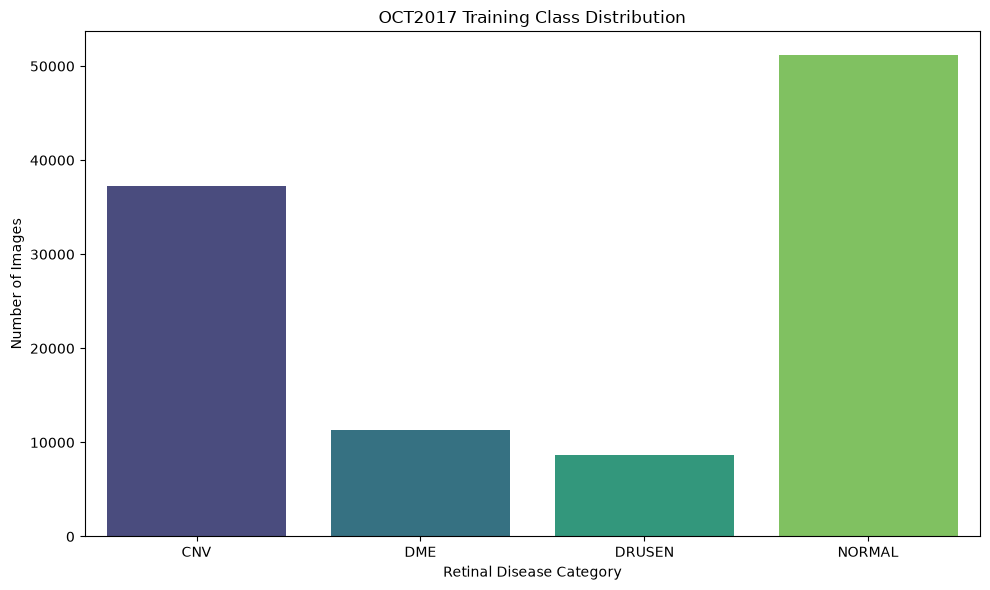

In [4]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=distribution,
    x="Class",
    y="Train",
    hue="Class",
    palette="viridis",
    legend=False
)

plt.title("OCT2017 Training Class Distribution")
plt.xlabel("Retinal Disease Category")
plt.ylabel("Number of Images")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "class_distribution.png",
    dpi=300
)

plt.show()


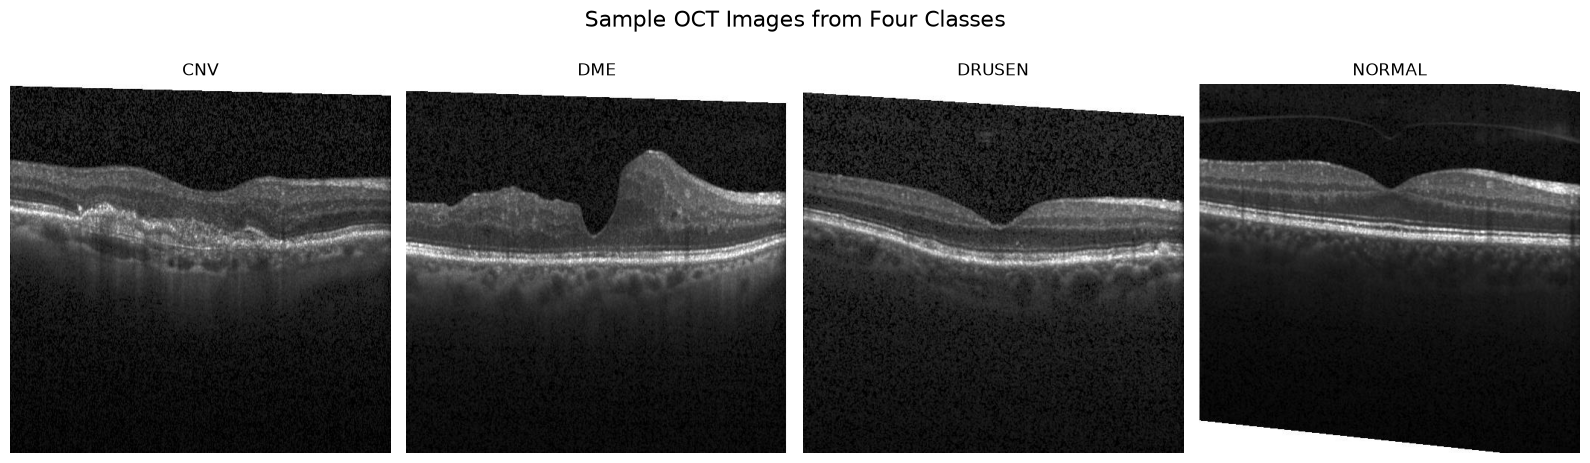

In [6]:

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for class_id, class_name in enumerate(class_names):

    index = next(
        i for i, label in enumerate(train_data["label"])
        if label == class_id
    )

    image = train_data[index]["image"]

    axes[class_id].imshow(image, cmap="gray")
    axes[class_id].set_title(class_name)
    axes[class_id].axis("off")

plt.suptitle(
    "Sample OCT Images from Four Classes",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "sample_oct_images.png",
    dpi=300
)

plt.show()


In [7]:

rng = np.random.default_rng(42)

sample_indices = rng.choice(
    len(train_data),
    size=min(1000, len(train_data)),
    replace=False
)

image_details = []

for index in sample_indices:
    sample = train_data[int(index)]
    image = sample["image"]

    image_details.append({
        "width": image.width,
        "height": image.height,
        "mode": image.mode,
        "class": class_names[sample["label"]]
    })

image_df = pd.DataFrame(image_details)

display(image_df.describe(include="all"))

image_df.to_csv(
    METRICS_DIR / "image_dimensions_sample.csv",
    index=False
)


,width,height,mode,class
count,1000.000000,1000.000000,1000,1000
unique,NaN,NaN,1,4
top,NaN,NaN,L,NORMAL
freq,NaN,NaN,1000,480
mean,713.472000,497.040000,NaN,NaN
std,330.160044,3.946387,NaN,NaN
min,512.000000,496.000000,NaN,NaN
25%,512.000000,496.000000,NaN,NaN
50%,512.000000,496.000000,NaN,NaN
75%,768.000000,496.000000,NaN,NaN


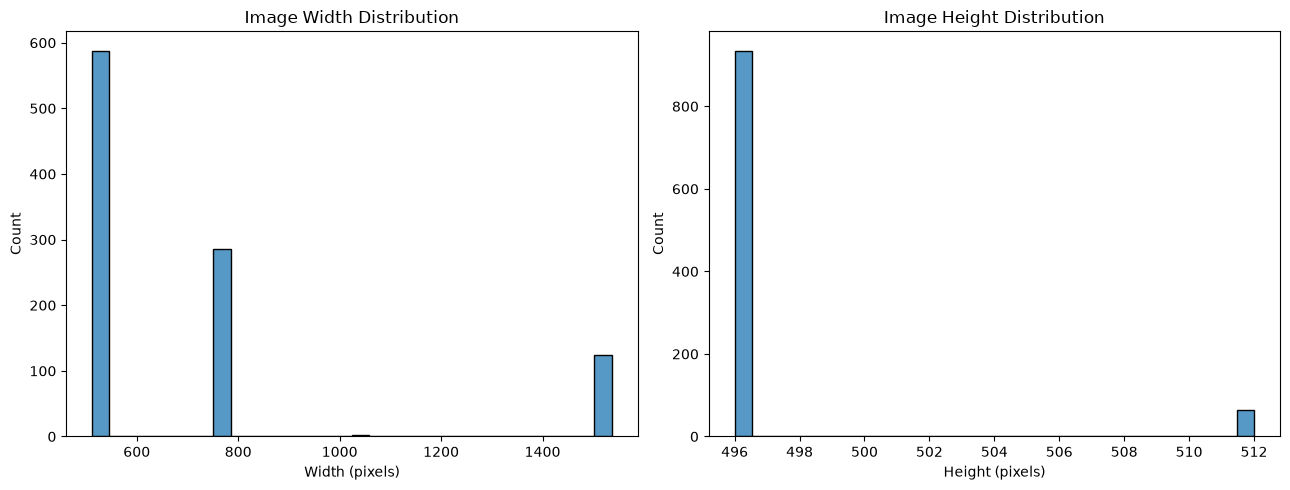

In [8]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    image_df["width"],
    bins=30,
    ax=axes[0]
)

axes[0].set_title("Image Width Distribution")
axes[0].set_xlabel("Width (pixels)")

sns.histplot(
    image_df["height"],
    bins=30,
    ax=axes[1]
)

axes[1].set_title("Image Height Distribution")
axes[1].set_xlabel("Height (pixels)")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "image_dimensions.png",
    dpi=300
)

plt.show()


In [9]:

from collections import Counter

print("Dataset columns:", train_data.column_names)
print("Dataset features:", train_data.features)

print("\nFirst sample metadata:")
sample = train_data[0]

for key, value in sample.items():
    if key == "image":
        print("image:", type(value).__name__)
        print("image size:", value.size)
    else:
        print(key, ":", value)

print("\nUnderlying image storage:")
raw_sample = train_data.with_format("arrow")[0]
print(raw_sample)


Dataset columns: ['image', 'label']
Dataset features: {'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['CNV', 'DME', 'DRUSEN', 'NORMAL'])}

First sample metadata:
image: JpegImageFile
image size: (512, 496)
label : 0

Underlying image storage:
pyarrow.Table
image: struct<bytes: binary, path: string>
  child 0, bytes: binary
  child 1, path: string
label: int64
----
image: [
  -- is_valid: all not null
  -- child 0 type: binary
[FFD8FFE000104A46494600010100000100010000FFDB004300080606070605080707070909080A0C140D0C0B0B0C1912130F (... 95362 chars omitted)]
  -- child 1 type: string
["CNV-1016042-1.jpeg"]]
label: [[0]]


In [13]:

from pathlib import PurePosixPath
import re
import pandas as pd

# Extract filenames without loading image pixels
def get_image_path(dataset, index):
    row = dataset.data.slice(index, 1).to_pylist()[0]
    return row["image"]["path"]


print("First 10 training filenames:")
for i in range(10):
    print(get_image_path(train_data, i))

print("\nFirst 10 testing filenames:")
for i in range(10):
    print(get_image_path(test_data, i))


# Analyze filenames safely
records = []

for split_name, dataset in [
    ("train", train_data),
    ("test", test_data)
]:
    print(f"\nProcessing {split_name} filenames...")

    image_column = dataset.data.column("image")
    label_column = dataset.data.column("label")

    # Process Arrow chunks separately
    # Avoid combine_chunks() to prevent offset overflow
    for chunk_index in range(image_column.num_chunks):

        image_chunk = image_column.chunk(chunk_index)
        label_chunk = label_column.chunk(chunk_index)

        paths = image_chunk.field("path").to_pylist()
        labels = label_chunk.to_pylist()

        for path, label in zip(paths, labels):

            filename = PurePosixPath(path or "").name

            match = re.match(
                r"^([A-Za-z]+)-(\d+)-(.+)\.(jpe?g|png)$",
                filename,
                flags=re.IGNORECASE
            )

            records.append({
                "split": split_name,
                "filename": filename,
                "class": class_names[label],
                "identifier": (
                    match.group(2) if match else None
                ),
                "valid_pattern": bool(match)
            })

    print(f"{split_name} processing completed!")


metadata_df = pd.DataFrame(records)

print("\nFilename pattern summary:")
print(
    metadata_df.groupby("split")["valid_pattern"]
    .value_counts()
)

print("\nExamples of unmatched filenames:")
display(
    metadata_df[
        ~metadata_df["valid_pattern"]
    ].head(20)
)

print("\nUnique identifiers per split:")
print(
    metadata_df.groupby("split")["identifier"].nunique()
)

# Save metadata
METRICS_DIR.mkdir(parents=True, exist_ok=True)

metadata_df.to_csv(
    METRICS_DIR / "image_metadata.csv",
    index=False
)

print("\nMetadata saved successfully!")
print("Total records:", len(metadata_df))


First 10 training filenames:
CNV-1016042-1.jpeg
CNV-1016042-10.jpeg
CNV-1016042-100.jpeg
CNV-1016042-101.jpeg
CNV-1016042-102.jpeg
CNV-1016042-103.jpeg
CNV-1016042-104.jpeg
CNV-1016042-105.jpeg
CNV-1016042-106.jpeg
CNV-1016042-107.jpeg

First 10 testing filenames:
CNV-1032178-1.jpeg
CNV-1034361-1.jpeg
CNV-1034361-2.jpeg
CNV-1052341-1.jpeg
CNV-1106195-1.jpeg
CNV-1106195-2.jpeg
CNV-1106195-3.jpeg
CNV-1106195-4.jpeg
CNV-1106195-5.jpeg
CNV-111867-1.jpeg

Processing train filenames...
train processing completed!

Processing test filenames...
test processing completed!

Filename pattern summary:
split  valid_pattern
test   True               1000
train  True             108309
Name: count, dtype: int64

Examples of unmatched filenames:


,split,filename,class,identifier,valid_pattern



Unique identifiers per split:
split
test      635
train    4785
Name: identifier, dtype: int64

Metadata saved successfully!
Total records: 109309


In [14]:

train_ids = set(
    metadata_df.loc[
        metadata_df["split"] == "train",
        "identifier"
    ].dropna()
)

test_ids = set(
    metadata_df.loc[
        metadata_df["split"] == "test",
        "identifier"
    ].dropna()
)

overlap = train_ids & test_ids

print("Training identifiers:", len(train_ids))
print("Testing identifiers:", len(test_ids))
print("Overlapping identifiers:", len(overlap))

if overlap:
    print("WARNING: Potential patient overlap detected!")
    print("Example IDs:", sorted(overlap)[:10])
else:
    print("No extracted identifier overlap detected.")


Training identifiers: 4785
Testing identifiers: 635
Overlapping identifiers: 0
No extracted identifier overlap detected.


In [15]:

valid_df = metadata_df.dropna(subset=["identifier"])

class_counts_per_id = (
    valid_df.groupby("identifier")["class"].nunique()
)

print(
    "Identifiers appearing in multiple classes:",
    (class_counts_per_id > 1).sum()
)

print("\nImages per identifier:")
print(
    valid_df.groupby("identifier")
    .size()
    .describe()
)

print("\nUnmatched filenames:")
print((~metadata_df["valid_pattern"]).sum())


Identifiers appearing in multiple classes: 787

Images per identifier:
count    5420.000000
mean       20.167712
std        39.081167
min         1.000000
25%         6.000000
50%        10.000000
75%        20.000000
max       813.000000
dtype: float64

Unmatched filenames:
0


In [16]:

import numpy as np
import pandas as pd

split_file = (
    PROJECT_ROOT / "data" / "processed" / "split_indices.npz"
)

splits = np.load(split_file)

train_idx = splits["train_idx"]
val_idx = splits["val_idx"]

labels = np.asarray(train_data["label"])

rows = []

for name, indices in [
    ("Train", train_idx),
    ("Validation", val_idx)
]:
    counts = np.bincount(
        labels[indices],
        minlength=len(class_names)
    )

    for class_id, count in enumerate(counts):
        rows.append({
            "Split": name,
            "Class": class_names[class_id],
            "Images": int(count),
            "Percentage": round(
                count / len(indices) * 100, 2
            )
        })

split_distribution = pd.DataFrame(rows)

display(
    split_distribution.pivot(
        index="Class",
        columns="Split",
        values="Images"
    )
)

display(
    split_distribution.pivot(
        index="Class",
        columns="Split",
        values="Percentage"
    )
)

split_distribution.to_csv(
    METRICS_DIR / "split_class_distribution.csv",
    index=False
)


Split,Train,Validation
Class,,
CNV,27971,9234
DME,9691,1657
DRUSEN,6818,1798
NORMAL,40967,10173


Split,Train,Validation
Class,,
CNV,32.73,40.39
DME,11.34,7.25
DRUSEN,7.98,7.86
NORMAL,47.94,44.50


In [19]:

import pandas as pd
from pathlib import Path

# Find the project directory
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Load previously saved image quality results
quality_path = (
    PROJECT_ROOT
    / "outputs"
    / "metrics"
    / "image_quality_sample.csv"
)

if quality_path.exists():

    quality_df = pd.read_csv(quality_path)

    print("=" * 50)
    print("OCT IMAGE QUALITY CHECK")
    print("=" * 50)

    print("Images checked:", len(quality_df))

    if "is_blank" in quality_df.columns:

        blank_count = (
            quality_df["is_blank"]
            .astype(str)
            .str.lower()
            .eq("true")
            .sum()
        )

        print("Blank images detected:", blank_count)

        if blank_count == 0:
            print("PASS: No blank images in checked sample.")
        else:
            print("WARNING: Blank images detected.")

    else:
        print("Available columns:", quality_df.columns.tolist())
        print("Column 'is_blank' was not found.")

    print("\nImage quality summary:")
    display(quality_df.describe(include="all"))

else:
    print("ERROR: Image quality CSV not found.")
    print("Expected path:", quality_path)
    print("Run the earlier image quality EDA cell first.")


ERROR: Image quality CSV not found.
Expected path: d:\GUVI\project_4\Retinal_Disease_Detection\outputs\metrics\image_quality_sample.csv
Run the earlier image quality EDA cell first.


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
from datasets import load_from_disk
from tqdm import tqdm
# Project directory
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "oct2017"
OUTPUT_PATH = (
    PROJECT_ROOT
    / "outputs"
    / "metrics"
    / "image_quality_sample.csv"
)

OUTPUT_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

# Load the existing dataset
dataset = load_from_disk(str(DATA_PATH))
train_data = dataset["train"]

# Reproducible sample of 1000 images
rng = np.random.default_rng(42)

sample_size = min(1000, len(train_data))

sample_indices = rng.choice(
    len(train_data),
    size=sample_size,
    replace=False
)

results = []

print("Checking OCT image quality...")

for idx in tqdm(sample_indices):
    sample = train_data[int(idx)]

    image = sample["image"].convert("L")
    image_array = np.asarray(image)

    mean_intensity = float(image_array.mean())
    std_intensity = float(image_array.std())

    # Simple blank-image screening
    is_blank = std_intensity < 2.0

    results.append({
        "image_index": int(idx),
        "label": int(sample["label"]),
        "width": image.width,
        "height": image.height,
        "mean_intensity": mean_intensity,
        "std_intensity": std_intensity,
        "is_blank": bool(is_blank)
    })

quality_df = pd.DataFrame(results)

quality_df.to_csv(
    OUTPUT_PATH,
    index=False
)

print("\n" + "=" * 55)
print("OCT IMAGE QUALITY REPORT")
print("=" * 55)

print("Images checked:", len(quality_df))
print(
    "Potentially blank images:",
    int(quality_df["is_blank"].sum())
)

print("\nImage intensity statistics:")
print(
    quality_df[
        ["mean_intensity", "std_intensity"]
    ].describe()
)

print("\nSaved report:")
print(OUTPUT_PATH)


: 